In [ ]:
#hola david, espero que estés viendo esto. aquí voy a hacer las cosas del trabajo.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar los datos
df = pd.read_csv('C:\\Users\\PC\\4º\\FNP\\taus_grupo_02.csv')


# Información general
print(f"Total de filas (partículas): {df.shape[0]}")
print(f"Total de eventos únicos: {df['event'].nunique()}")

print("\nNúmero de partículas de cada tipo:")
print(df['particleName'].value_counts())

# Mostramos las primeras filas
display(df.head())

Total de filas (partículas): 43931
Total de eventos únicos: 18367

Número de partículas de cada tipo:
particleName
gamma    22128
pi-      10258
pi+       6025
e-        1810
mu-       1747
e+        1068
mu+        895
Name: count, dtype: int64


,event,particleName,x,y,z,px,py,pz,E
0,0,mu+,-43.408935,-16.901364,18.166131,-17018.450594,-6618.204072,7118.046762,19598.623400
1,1,gamma,30.707234,-1.820474,-39.417657,8712.912935,-519.516755,-11172.361432,14177.672920
2,1,gamma,30.015386,-3.910669,-39.796775,375.055987,-49.391087,-496.982280,624.578145
3,1,pi+,27.947525,0.638501,-41.455135,8982.901644,213.465898,-13339.083370,16083.802865
4,2,pi-,22.642957,-42.917442,12.057766,10621.031592,-20121.148546,5656.243957,23445.244857


Preparación y limpieza de los datos

Antes de aplicar los algoritmos de Machine Learning, es necesario preparar el conjunto de datos para garantizar que la información utilizada sea adecuada.

En esta etapa se realizará una exploración inicial de las variables, se comprobará la existencia de filas duplicadas y valores ausentes y se estudiará la distribución de las variables categóricas.

También se analizarán los posibles valores atípicos (outliers) mediante el rango intercuartílico (IQR) y el método del Z-score. Estos procedimientos permiten identificar observaciones que se alejan considerablemente de la distribución general de los datos.

Es importante tener en cuenta que, en un conjunto de datos de física de partículas, los valores extremos pueden corresponder a fenómenos físicos reales y no necesariamente a errores experimentales. Por este motivo, su eliminación deberá estar justificada.

In [3]:
# Dimensiones iniciales
print("Dimensiones iniciales:", df.shape)

# Primeras filas
display(df.head())

# Información de las variables
df.info()

# Eliminación de duplicados
df = df.drop_duplicates()

print("\nDimensiones tras eliminar duplicados:", df.shape)

# Número de valores ausentes por columna
columns_na = df.isna().sum().sort_values(ascending=False)

# Porcentaje de valores ausentes
porcentaje_na = (columns_na / len(df)) * 100

print("Valores ausentes por columna:")
print(porcentaje_na[porcentaje_na > 0])

# Comprobamos si existen valores nulos en particleName
if df['particleName'].isna().any():
    mode_particle = df['particleName'].mode()[0]
    df['particleName'] = df['particleName'].fillna(mode_particle)

print("\nValores nulos restantes:", df.isna().sum().sum())

# Codificación numérica de las partículas
df['particleName_codes'] = (df['particleName'].astype('category').cat.codes)

print("Codificación de partículas:")
print(
    df[['particleName', 'particleName_codes']].drop_duplicates().sort_values('particleName_codes'))

# One-Hot Encoding
particle_dummies = pd.get_dummies(
    df['particleName'], prefix='particle', dtype=int)

print("\nVariables generadas mediante One-Hot Encoding:")
display(particle_dummies.head())

# Seleccionamos la energía
sP = df['E']

# Calculamos los cuartiles
Q1 = sP.quantile(0.25)
Q3 = sP.quantile(0.75)

# Calculamos el rango intercuartílico
IQR = Q3 - Q1

# Límites para detectar posibles outliers
lim_inf = Q1 - 1.5 * IQR
lim_sup = Q3 + 1.5 * IQR

# Identificamos los valores atípicos
outliers_IQR = df[(df['E'] < lim_inf) | (df['E'] > lim_sup)]

print("Límite inferior:", lim_inf)
print("Límite superior:", lim_sup)
print("Número de posibles outliers:", len(outliers_IQR))

from scipy import stats

# Calculamos el Z-score de la energía
z = np.abs(stats.zscore(df['E']))

# Identificamos los valores situados a más de 3 desviaciones estándar
outliers_z = df[z > 3]

print("Número de posibles outliers mediante Z-score:", len(outliers_z))

Dimensiones iniciales: (43931, 9)


,event,particleName,x,y,z,px,py,pz,E
0,0,mu+,-43.408935,-16.901364,18.166131,-17018.450594,-6618.204072,7118.046762,19598.623400
1,1,gamma,30.707234,-1.820474,-39.417657,8712.912935,-519.516755,-11172.361432,14177.672920
2,1,gamma,30.015386,-3.910669,-39.796775,375.055987,-49.391087,-496.982280,624.578145
3,1,pi+,27.947525,0.638501,-41.455135,8982.901644,213.465898,-13339.083370,16083.802865
4,2,pi-,22.642957,-42.917442,12.057766,10621.031592,-20121.148546,5656.243957,23445.244857


<class 'pandas.DataFrame'>
RangeIndex: 43931 entries, 0 to 43930
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   event         43931 non-null  int64  
 1   particleName  43931 non-null  str    
 2   x             43931 non-null  float64
 3   y             43931 non-null  float64
 4   z             43931 non-null  float64
 5   px            43931 non-null  float64
 6   py            43931 non-null  float64
 7   pz            43931 non-null  float64
 8   E             43931 non-null  float64
dtypes: float64(7), int64(1), str(1)
memory usage: 3.0 MB



Dimensiones tras eliminar duplicados: (43931, 9)
Valores ausentes por columna:
Series([], dtype: float64)

Valores nulos restantes: 0
Codificación de partículas:
   particleName  particleName_codes
62           e+                   0
17           e-                   1
1         gamma                   2
0           mu+                   3
11          mu-                   4
3           pi+                   5
4           pi-                   6

Variables generadas mediante One-Hot Encoding:


,particle_e+,particle_e-,particle_gamma,particle_mu+,particle_mu-,particle_pi+,particle_pi-
0,0,0,0,1,0,0,0
1,0,0,1,0,0,0,0
2,0,0,1,0,0,0,0
3,0,0,0,0,0,1,0
4,0,0,0,0,0,0,1


Límite inferior: -17713.341819641788
Límite superior: 37858.55906996889
Número de posibles outliers: 1064
Número de posibles outliers mediante Z-score: 368


Análisis mediante regresión lineal

En primer lugar, estudiaremos las relaciones existentes entre las variables numéricas del conjunto de datos mediante una matriz de correlación.

Posteriormente, aplicaremos un modelo de regresión lineal para investigar la relación entre el momento de las partículas y su energía.

Este análisis permitirá comprobar si un modelo lineal es suficiente para describir dicha relación o si es necesario utilizar modelos más complejos capaces de representar comportamientos no lineales.

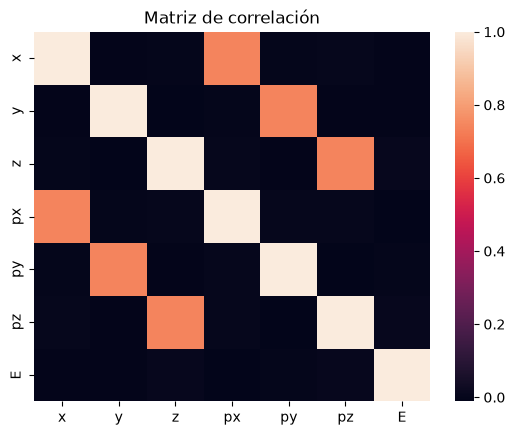

In [4]:

# MATRIZ DE CORRELACIÓN
# Solo podemos correlacionar columnas numéricas
a = df[['x', 'y', 'z', 'px', 'py', 'pz', 'E']].corr()
sns.heatmap(a, annot=False)
plt.title('Matriz de correlación')
plt.show()


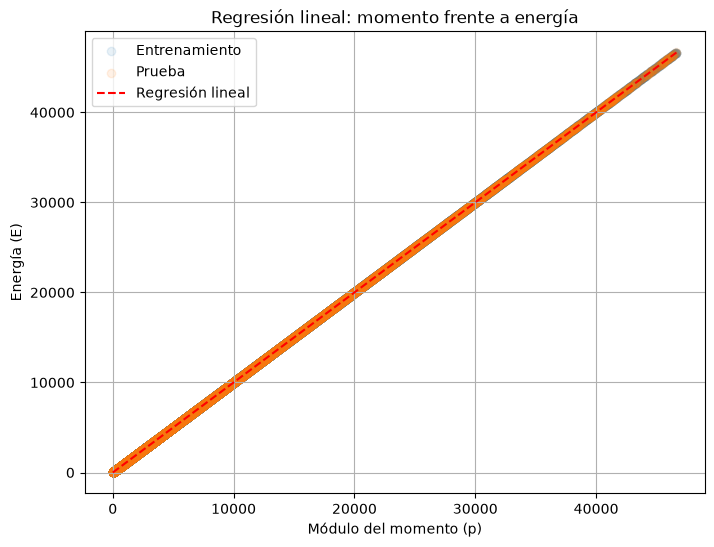

R² entrenamiento: 0.9999999764528992
R² prueba: 0.9999999745448926


In [5]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Calculamos el módulo del momento
df['p'] = np.sqrt(
    df['px']**2 + df['py']**2 + df['pz']**2
)

# Variable predictora: módulo del momento
X = df[['p']].values

# Variable objetivo: energía
y = df['E'].values

# Identificador de evento
groups = df['event'].values

# División de entrenamiento y prueba por eventos
splitter = GroupShuffleSplit(n_splits=1, test_size=0.33, random_state=100)

train_idx, test_idx = next(splitter.split(X, y, groups))

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

# Entrenamiento del modelo
reg = LinearRegression()
reg.fit(X_train, y_train)

# Predicciones
y_train_hat = reg.predict(X_train)
y_test_hat = reg.predict(X_test)

# Representación gráfica
plt.figure(figsize=(8, 6))

plt.scatter(X_train, y_train, alpha=0.1, label='Entrenamiento')

plt.scatter(X_test, y_test, alpha=0.1, label='Prueba')

X_plot = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)

y_plot = reg.predict(X_plot)

plt.plot(X_plot, y_plot, 'r--', label='Regresión lineal')

plt.xlabel('Módulo del momento (p)')
plt.ylabel('Energía (E)')
plt.title('Regresión lineal: momento frente a energía')
plt.legend()
plt.grid(True)
plt.show()

# Evaluación
print("R² entrenamiento:", r2_score(y_train, y_train_hat))
print("R² prueba:", r2_score(y_test, y_test_hat))

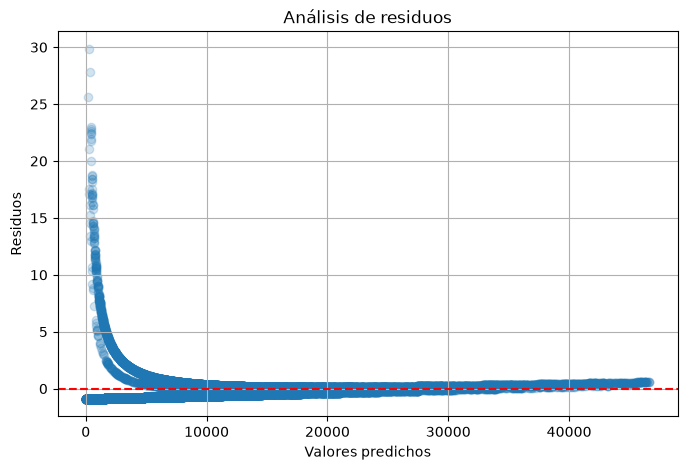

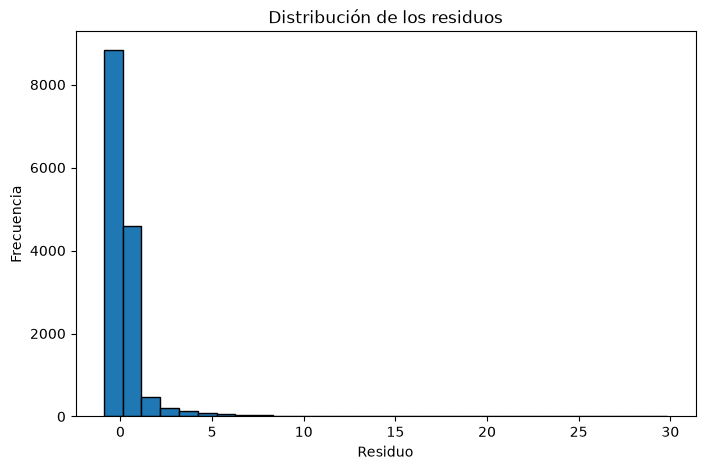

In [6]:
# Calculamos los residuos
residuos = y_test - y_test_hat

# Residuos frente a predicciones
plt.figure(figsize=(8, 5))

plt.scatter(y_test_hat, residuos, alpha=0.2)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Valores predichos')
plt.ylabel('Residuos')
plt.title('Análisis de residuos')
plt.grid(True)
plt.show()

# Histograma de residuos
plt.figure(figsize=(8, 5))

plt.hist(residuos, bins=30, edgecolor='black')

plt.xlabel('Residuo')
plt.ylabel('Frecuencia')
plt.title('Distribución de los residuos')
plt.show()

Interpretación de los resultados

La regresión lineal permite estudiar la relación entre el módulo del momento y la energía de las partículas.

Sin embargo, la relación relativista entre ambas magnitudes es no lineal, ya que también depende de la masa de la partícula.

Por este motivo, un modelo de regresión lineal puede no ser suficiente para describir correctamente los datos.

Este resultado justifica la utilización posterior de algoritmos más complejos, como las Máquinas de Soporte Vectorial y las redes neuronales artificiales, que permiten estudiar relaciones más complejas entre las variables físicas.

Clasificación mediante Máquinas de Soporte Vectorial (SVM)

Una vez estudiadas las relaciones entre las variables físicas mediante regresión lineal, abordaremos un problema de clasificación binaria.

El objetivo será diferenciar entre muones y piones a partir de sus propiedades cinemáticas.

Para ello utilizaremos un algoritmo de Máquinas de Soporte Vectorial (SVM), implementado mediante el clasificador SGDClassifier con función de pérdida hinge.

Este algoritmo buscará establecer una frontera de decisión que permita separar ambas clases.

Primero prepararemos las variables de entrada y las etiquetas, después escalaremos los datos y seleccionaremos el hiperparámetro de regularización mediante validación cruzada.

Distribución de las clases:
target
0    16283
1     2642
Name: count, dtype: int64

Número de partículas: 18925
Número de eventos: 15733


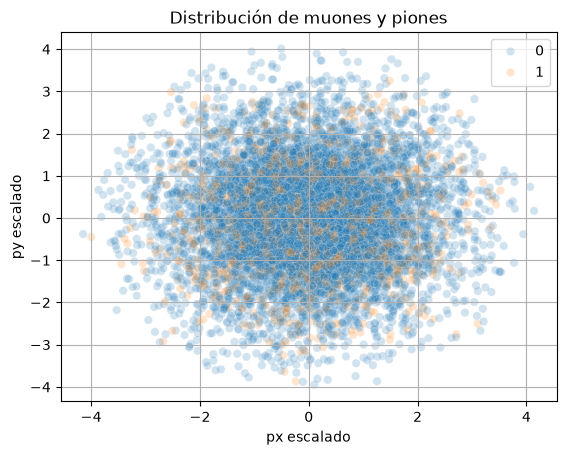

In [7]:
from sklearn import linear_model
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import GroupShuffleSplit

# Seleccionamos únicamente muones y piones
df_filtrado = df[df['particleName'].isin(['mu+', 'mu-', 'pi+', 'pi-'])].copy()

# Creamos la variable objetivo
# 1 = muón
# 0 = pión

df_filtrado['target'] = df_filtrado['particleName'].apply(lambda x: 1 if x.startswith('mu') else 0)

# Variables predictoras
X = df_filtrado[['px', 'py']].values

# Variable objetivo
y = df_filtrado['target'].values

# Identificador de evento
groups = df_filtrado['event'].values

# Comprobamos el número de partículas de cada clase
print("Distribución de las clases:")
print(df_filtrado['target'].value_counts())

print("\nNúmero de partículas:", len(df_filtrado))
print("Número de eventos:", df_filtrado['event'].nunique())

# Separamos entrenamiento y prueba por eventos
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)

train_idx, test_idx = next(splitter.split(X, y, groups))

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

groups_train = groups[train_idx]

# Escalado de variables
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Representación gráfica
sns.scatterplot(x=X_train_scaled[:, 0], y=X_train_scaled[:, 1], hue=y_train, alpha=0.2)

plt.xlabel('px escalado')
plt.ylabel('py escalado')
plt.title('Distribución de muones y piones')
plt.grid(True)
plt.show()


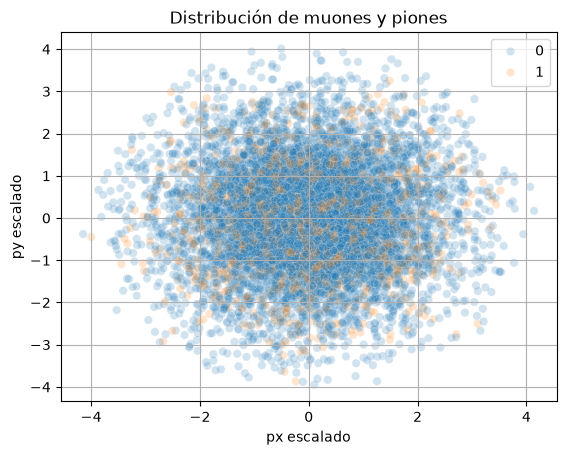

In [8]:
# Separamos entrenamiento y prueba por eventos
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)

train_idx, test_idx = next(splitter.split(X, y, groups))

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

groups_train = groups[train_idx]

# Escalado de variables
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Representación gráfica
sns.scatterplot(x=X_train_scaled[:, 0], y=X_train_scaled[:, 1], hue=y_train, alpha=0.2)

plt.xlabel('px escalado')
plt.ylabel('py escalado')
plt.title('Distribución de muones y piones')
plt.grid(True)
plt.show()

Mejor alpha: 1e-05
Mejor accuracy de validación: 0.8615159324369916


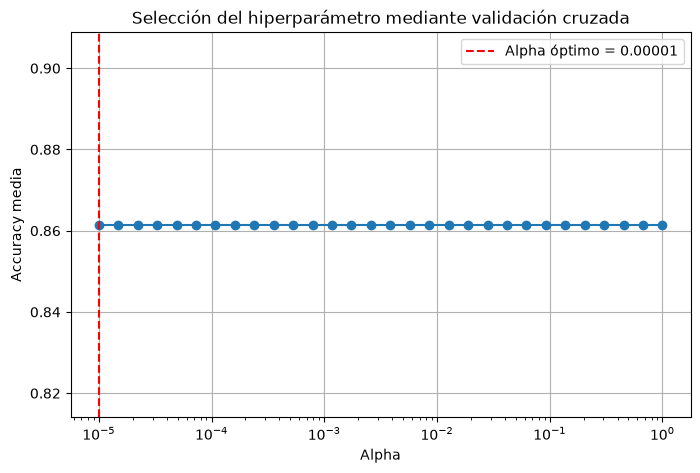

In [9]:
# Valores de alpha que vamos a probar
alpha = np.logspace(-5, 0, 30)

val_scores = []

# Validación cruzada agrupada por eventos
cv = GroupKFold(n_splits=5)

for a in alpha:

    model = make_pipeline(StandardScaler(), linear_model.SGDClassifier(loss='hinge', penalty='l2', alpha=a, random_state=42, max_iter=2000, tol=1e-4))

    scores = cross_val_score(model, X_train, y_train, groups=groups_train, cv=cv, scoring='accuracy')

    val_scores.append(scores.mean())

# Mejor alpha
ind = np.argmax(val_scores)
alpha_star = alpha[ind]

print("Mejor alpha:", alpha_star)
print("Mejor accuracy de validación:", val_scores[ind])

# Representación
plt.figure(figsize=(8, 5))

plt.semilogx(
    alpha,
    val_scores,
    marker='o'
)

plt.axvline(
    alpha_star,
    color='red',
    linestyle='--',
    label=f'Alpha óptimo = {alpha_star:.5f}'
)

plt.xlabel('Alpha')
plt.ylabel('Accuracy media')
plt.title('Selección del hiperparámetro mediante validación cruzada')
plt.legend()
plt.grid(True)
plt.show()

In [10]:
# Creamos el modelo con el mejor alpha
model_star = make_pipeline(
    StandardScaler(),
    linear_model.SGDClassifier(
        loss='hinge',
        penalty='l2',
        alpha=alpha_star,
        random_state=42,
        max_iter=2000,
        tol=1e-4
    )
)

# Entrenamiento
model_star.fit(X_train, y_train)

# Predicciones
y_pred_train = model_star.predict(X_train)
y_pred_test = model_star.predict(X_test)

# Evaluación
print(
    "Accuracy de entrenamiento:",
    accuracy_score(y_train, y_pred_train)
)

print(
    "Accuracy de prueba:",
    accuracy_score(y_test, y_pred_test)
)

print("\nInforme de clasificación:")
print(
    classification_report(
        y_test,
        y_pred_test,
        target_names=['Piones', 'Muones']
    )
)

Accuracy de entrenamiento: 0.861515727253536
Accuracy de prueba: 0.8570216376750106

Informe de clasificación:
              precision    recall  f1-score   support

      Piones       0.86      1.00      0.92      4040
      Muones       0.00      0.00      0.00       674

    accuracy                           0.86      4714
   macro avg       0.43      0.50      0.46      4714
weighted avg       0.73      0.86      0.79      4714



c:\Users\PC\AppData\Local\spyder-6\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\PC\AppData\Local\spyder-6\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\PC\AppData\Local\spyder-6\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0]

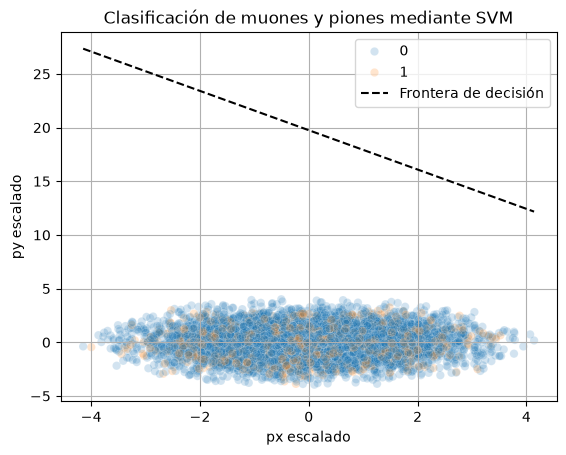

In [11]:
# Recuperamos el clasificador y el escalador del pipeline
scaler_svm = model_star.named_steps['standardscaler']
svm = model_star.named_steps['sgdclassifier']

# Utilizamos los datos escalados para representar la frontera
X_train_scaled = scaler_svm.transform(X_train)

# Coeficientes y término independiente
w = svm.coef_[0]
b = svm.intercept_[0]

# Generamos puntos para la recta
x1 = np.linspace(
    X_train_scaled[:, 0].min(),
    X_train_scaled[:, 0].max(),
    200
)

# Ecuación de la frontera de decisión
y1 = -(w[0] * x1 + b) / w[1]

# Representación
sns.scatterplot(
    x=X_train_scaled[:, 0],
    y=X_train_scaled[:, 1],
    hue=y_train,
    alpha=0.2
)

plt.plot(
    x1,
    y1,
    '--k',
    label='Frontera de decisión'
)

plt.xlabel('px escalado')
plt.ylabel('py escalado')
plt.title('Clasificación de muones y piones mediante SVM')
plt.legend()
plt.grid(True)
plt.show()

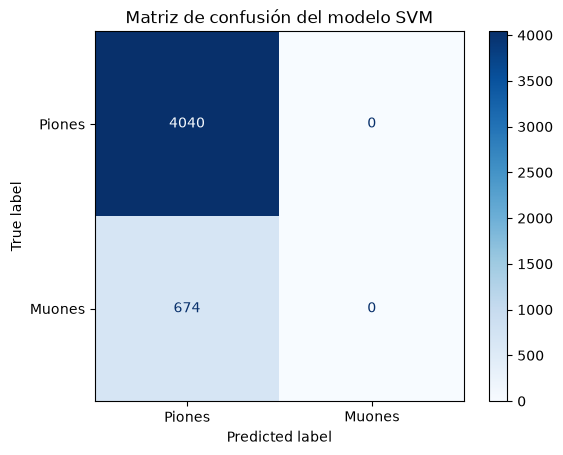

In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculamos la matriz de confusión
cm = confusion_matrix(y_test, y_pred_test)

# Representamos la matriz
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Piones', 'Muones']
)

disp.plot(cmap='Blues')

plt.title('Matriz de confusión del modelo SVM')
plt.show()

Árbol Regresión - R² train: 0.829
Árbol Regresión - R² test:  0.822


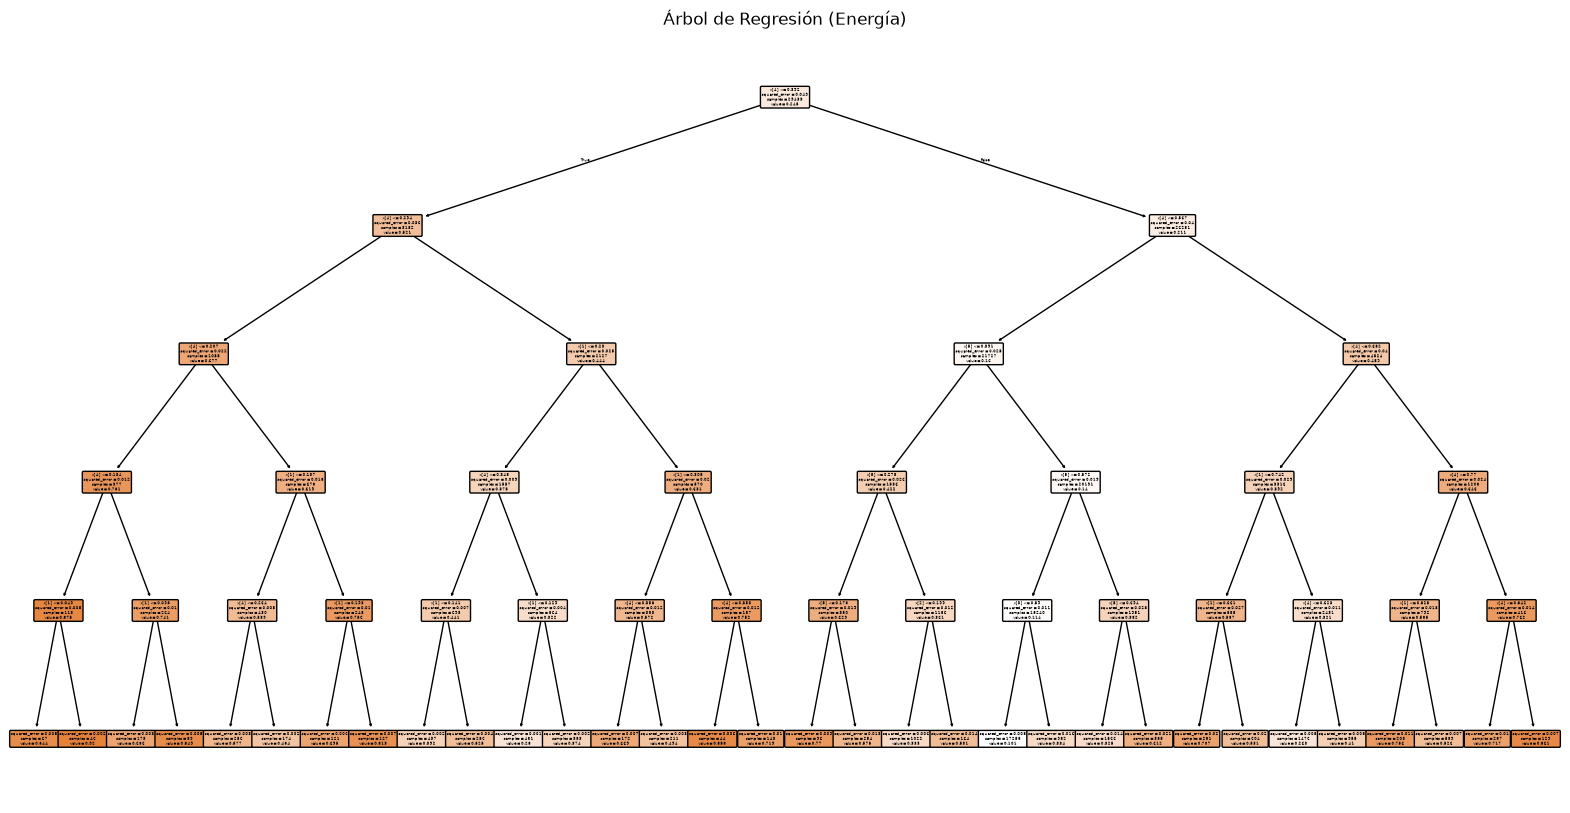

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# Separamos los datos para predecir la Energía (E)
# X_reg serán las posiciones y momentos (quitando E y el nombre)
X_reg = df[['x', 'y', 'z', 'px', 'py', 'pz']].values
y_reg = df['E'].values.reshape(-1, 1)

# Escalado y división (igual que en tu cuaderno)
X_scaler = MinMaxScaler()
y_scaler = MinMaxScaler()
X_reg = X_scaler.fit_transform(X_reg)
y_reg = y_scaler.fit_transform(y_reg)

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.33, random_state=100)

# Creamos y entrenamos el árbol de regresión (max_depth=5 como en clase)
tree_5 = DecisionTreeRegressor(max_depth=5)
tree_5.fit(X_train_r, y_train_r.reshape(-1))

# Predicciones y cálculo del R²
y_train_hat_r = tree_5.predict(X_train_r)
y_test_hat_r = tree_5.predict(X_test_r)

print(f"Árbol Regresión - R² train: {r2_score(y_train_r, y_train_hat_r):.3f}")
print(f"Árbol Regresión - R² test:  {r2_score(y_test_r, y_test_hat_r):.3f}")

# Visualizar el árbol
from sklearn.tree import plot_tree
plt.figure(figsize=(20, 10))
plot_tree(tree_5, filled=True, rounded=True)
plt.title("Árbol de Regresión (Energía)")
plt.show()

Árbol Clasificación - Accuracy: 0.857

Matriz de confusión (Árbol):
[[4039    1]
 [ 674    0]]


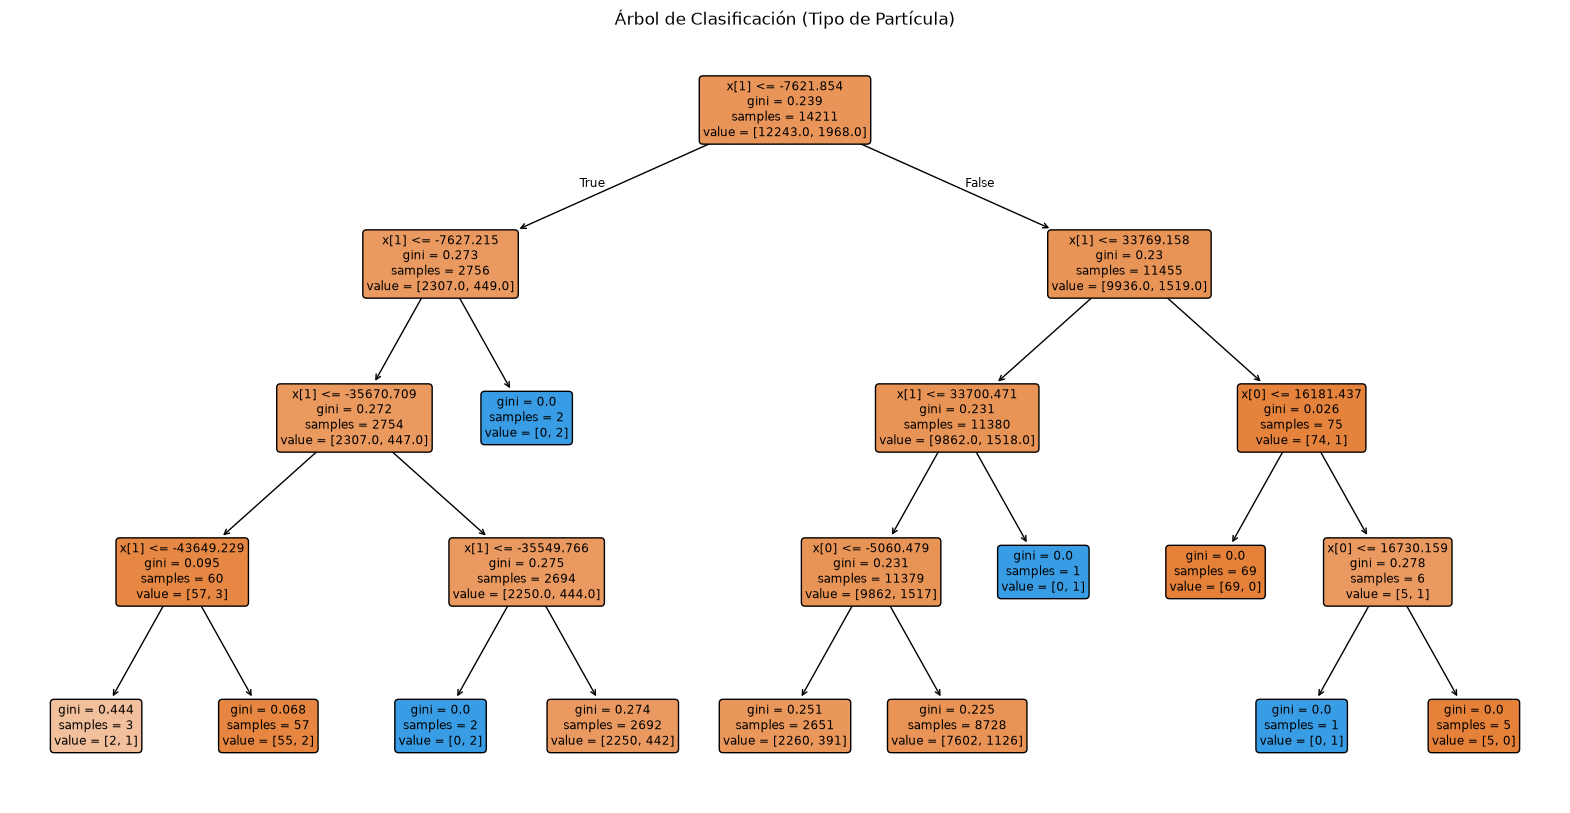

In [15]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# Crear el modelo igual que en clase (criterion="gini", max_depth=4)
drugTree = DecisionTreeClassifier(criterion="gini", max_depth=4)

# Entrenar
drugTree.fit(X_train, y_train)

# Predecir y evaluar
predTree = drugTree.predict(X_test)
print(f"Árbol Clasificación - Accuracy: {accuracy_score(y_test, predTree):.3f}")

# Matriz de confusión
print("\nMatriz de confusión (Árbol):")
print(confusion_matrix(y_test, predTree))

# Visualizar el árbol
plt.figure(figsize=(20, 10))
plot_tree(drugTree, filled=True, rounded=True)
plt.title("Árbol de Clasificación (Tipo de Partícula)")
plt.show()

In [16]:
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.optimizers import SGD

# El número de clases (partículas) será el número de valores únicos en y_train
n_clases = len(np.unique(y_train))

# Creación de la red (Igual que en tu cuaderno)
model = keras.Sequential([
    layers.Dense(20, activation='relu', input_shape=(X_train.shape[1],)),
    layers.Dense(20, activation='relu'),
    layers.Dense(20, activation='relu'),
    layers.Dense(n_clases, activation='softmax') # Salida para multiclase
])

# Compilación (Corregido para la versión actual de Keras)
sgd = SGD(learning_rate=0.1)
model.compile(optimizer=sgd,
              loss='sparse_categorical_crossentropy', # Pérdida para múltiples clases
              metrics=['accuracy'])

# Entrenamiento (500 épocas como pedía el cuaderno)
print("Entrenando la red neuronal...")
history = model.fit(X_train, y_train, epochs=500, batch_size=10, validation_split=0.2, verbose=0)
print("¡Entrenamiento completado!")

# Predicciones y evaluación
y_hat_test = np.argmax(model.predict(X_test), axis=1)

print(f"\nRed Neuronal - Accuracy: {accuracy_score(y_test, y_hat_test):.3f}")

print("\nMatriz de confusión (Red Neuronal):")
print(confusion_matrix(y_test, y_hat_test))

c:\Users\PC\AppData\Local\spyder-6\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Entrenando la red neuronal...
¡Entrenamiento completado!
148/148 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

Red Neuronal - Accuracy: 0.857

Matriz de confusión (Red Neuronal):
[[4040    0]
 [ 674    0]]


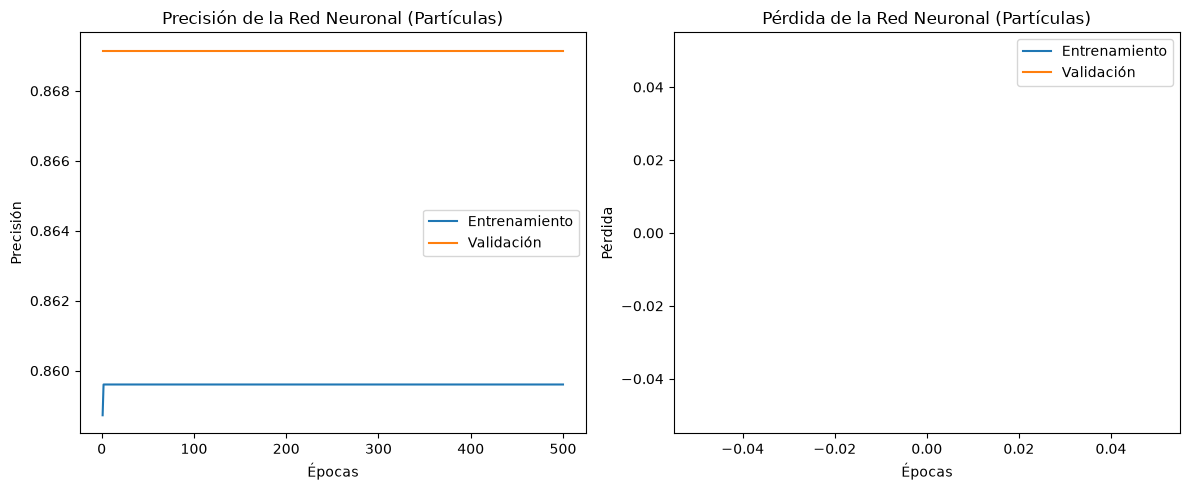

In [17]:
# Extraemos los datos del historial
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(acc) + 1)

# Gráfica de Accuracy (Precisión)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs, acc, label='Entrenamiento')
plt.plot(epochs, val_acc, label='Validación')
plt.title('Precisión de la Red Neuronal (Partículas)')
plt.xlabel('Épocas')
plt.ylabel('Precisión')
plt.legend()

# Gráfica de Loss (Pérdida)
plt.subplot(1, 2, 2)
plt.plot(epochs, loss, label='Entrenamiento')
plt.plot(epochs, val_loss, label='Validación')
plt.title('Pérdida de la Red Neuronal (Partículas)')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.legend()

plt.tight_layout()
plt.show()